# 05 · Emerging technologies

Sub-area (domain cluster) counts per year, the emerging list ranked by recent growth, the
back-test of the detection rule.
Produced by `python -m src.pipeline.trends`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
out = Path("data/outputs")
trends = pd.read_parquet(out / "trends.parquet")
emerging = pd.read_parquet(out / "emerging.parquet")
domain_trends = pd.read_parquet(out / "domain_trends.parquet")
bt = json.loads(Path("reports/trend_backtest.json").read_text())

## Domain volume over time (patents and papers)

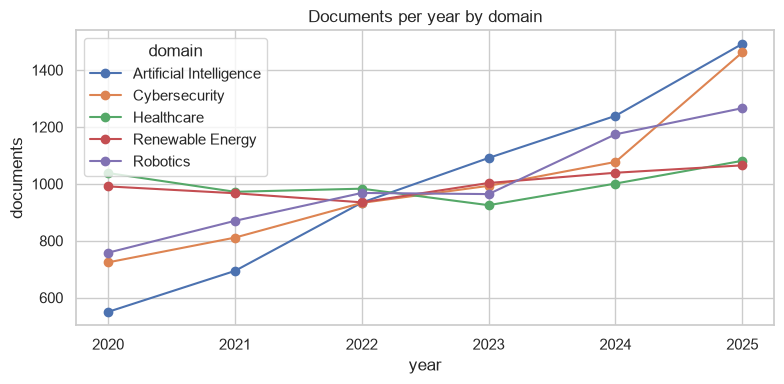

In [2]:
pivot = domain_trends.groupby(["year", "domain"])["count"].sum().unstack()
ax = pivot.plot(marker="o", figsize=(8, 4)); ax.set_ylabel("documents"); ax.set_title("Documents per year by domain")
plt.tight_layout(); plt.savefig(FIG / "domain_trends.png", dpi=150); plt.show()

## Emerging sub-areas
Ranked by recent growth, (n2024 + n2025 + 1) / (n2022 + n2023 + 1) − 1, among sub-areas with at
least 40 documents.

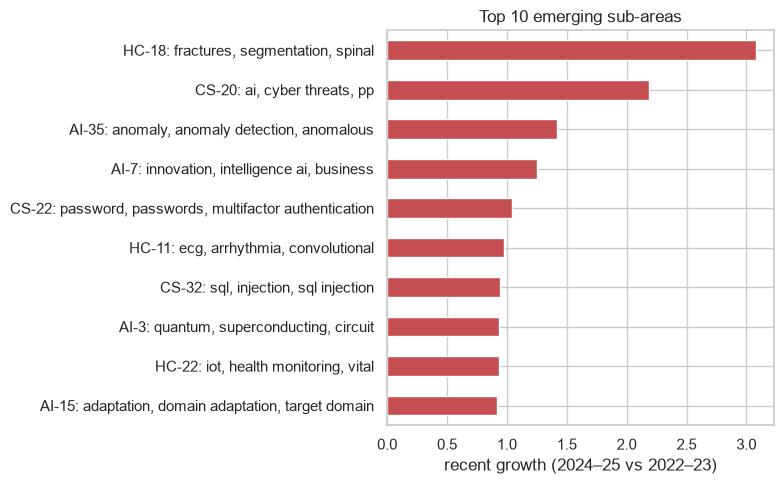

,cluster_id,domain,size,recent_growth,cagr
0,HC-18,Healthcare,82,3.0769,0.3356
1,CS-20,Cybersecurity,131,2.1852,0.3852
2,AI-35,Artificial Intelligence,44,1.4167,0.4465
3,AI-7,Artificial Intelligence,175,1.2500,0.4541
4,CS-22,Cybersecurity,98,1.0435,0.1636
5,HC-11,Healthcare,161,0.9787,0.3643
6,CS-32,Cybersecurity,75,0.9412,0.0313
7,AI-3,Artificial Intelligence,239,0.9355,0.2423
8,HC-22,Healthcare,132,0.9333,0.0810
9,AI-15,Artificial Intelligence,124,0.9167,0.3026


In [3]:
top = emerging.head(10).copy()
top["label"] = top["cluster_id"] + ": " + top["keywords"].map(lambda k: ", ".join(list(k)[:3]))
ax = top.set_index("label")["recent_growth"].sort_values().plot.barh(figsize=(8, 5), color="#C44E52")
ax.set_xlabel("recent growth (2024–25 vs 2022–23)"); ax.set_ylabel(""); ax.set_title("Top 10 emerging sub-areas")
plt.tight_layout(); plt.savefig(FIG / "emerging_top10.png", dpi=150); plt.show()
top[["cluster_id", "domain", "size", "recent_growth", "cagr"]]

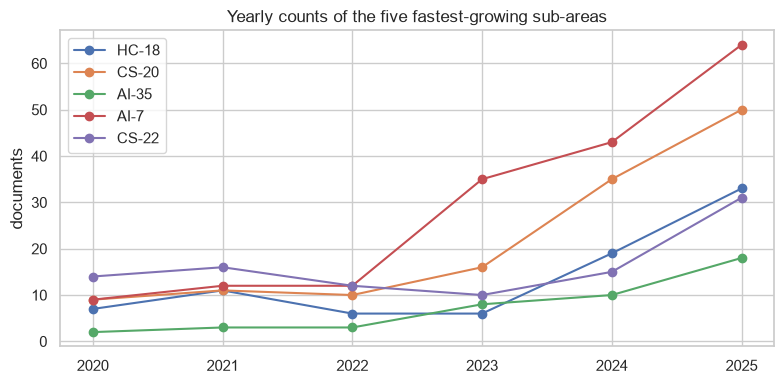

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for cid in top["cluster_id"].head(5):
    s = trends[trends["cluster_id"] == cid].set_index("year")["count"]
    ax.plot(s.index, s.values, marker="o", label=cid)
ax.set_ylabel("documents"); ax.set_title("Yearly counts of the five fastest-growing sub-areas"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "emerging_series.png", dpi=150); plt.show()

## Back-test of the detection rule
Clusters are flagged using 2020–2023 only, then checked against 2024–2025. A hit rate close to
the base rate means the two-year-window rule does not predict later growth better than chance:
most sub-areas grew over this period, and clusters of 40–200 documents give noisy yearly counts.

In [5]:
pd.Series({k: bt[k] for k in ("eligible_clusters", "flagged", "hit_rate", "base_rate_not_flagged",
                               "mean_later_growth_flagged", "mean_later_growth_not_flagged")})

eligible_clusters                157.0000
flagged                           20.0000
hit_rate                           0.7000
base_rate_not_flagged              0.6934
mean_later_growth_flagged          0.2198
mean_later_growth_not_flagged      0.2518
dtype: float64